In [1]:
import numpy as np
import pandas as pd

In [2]:
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.1.3
Pandas: 2.2.3


In [3]:

import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Everything is working!")

Everything is working!


In [4]:
train_df = pd.read_csv("Data/train (2).csv")

In [5]:
test_df = pd.read_csv("Data/test (2).csv")

In [6]:
train_df.head()

,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15709511.0,Ch'ang,754.0,Spain,Male,40.0,8.0,102954.68,2.0,1.0,1.0,149238.35,0.0
1,1,15592761.0,Genovese,579.0,France,Female,28.0,1.0,0.00,2.0,1.0,0.0,64869.32,0.0
2,2,15579914.0,Yeh,744.0,France,Female,56.0,5.0,0.00,1.0,1.0,0.0,158816.03,1.0
3,3,15669611.0,Nwachinemelu,697.0,France,Male,29.0,2.0,0.00,2.0,1.0,0.0,55775.72,0.0
4,4,15761775.0,Hs?eh,628.0,France,Female,22.0,9.0,0.00,2.0,1.0,0.0,49653.39,0.0


In [7]:
train_df.shape

(15000, 14)

In [8]:
test_df.shape

(10000, 13)

In [9]:
train_df.columns

Index(['id', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender',
       'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='object')

In [10]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               15000 non-null  int64  
 1   CustomerId       15000 non-null  float64
 2   Surname          15000 non-null  object 
 3   CreditScore      15000 non-null  float64
 4   Geography        15000 non-null  object 
 5   Gender           15000 non-null  object 
 6   Age              15000 non-null  float64
 7   Tenure           15000 non-null  float64
 8   Balance          15000 non-null  float64
 9   NumOfProducts    15000 non-null  float64
 10  HasCrCard        15000 non-null  float64
 11  IsActiveMember   15000 non-null  float64
 12  EstimatedSalary  15000 non-null  float64
 13  Exited           15000 non-null  float64
dtypes: float64(10), int64(1), object(3)
memory usage: 1.6+ MB


In [11]:
train_df.isnull().sum()

id                 0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [12]:
train_df['Exited'].value_counts()


Exited
0.0    11942
1.0     3058
Name: count, dtype: int64

In [13]:
train_df['Exited'].value_counts(normalize=True) * 100

Exited
0.0    79.613333
1.0    20.386667
Name: proportion, dtype: float64

In [14]:
train_df.describe()

,id,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,15000.000000,1.500000e+04,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,1.500000e+04,15000.000000
mean,7499.500000,1.579653e+07,658.851467,37.888000,5.033333,43124.060479,1.590733,0.783200,0.500200,1.181348e+05,0.203867
std,4330.271354,1.270937e+07,72.587026,8.257409,2.808359,59777.868496,0.535587,0.412079,0.500017,4.680311e+04,0.402884
min,0.000000,1.556578e+07,431.000000,18.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.158000e+01,0.000000
25%,3749.750000,1.563449e+07,602.000000,32.000000,3.000000,0.000000,1.000000,1.000000,0.000000,8.362960e+04,0.000000
50%,7499.500000,1.569053e+07,662.000000,37.000000,5.000000,0.000000,2.000000,1.000000,1.000000,1.235878e+05,0.000000
75%,11249.250000,1.575758e+07,709.000000,42.000000,7.000000,109650.982500,2.000000,1.000000,1.000000,1.575585e+05,0.000000
max,14999.000000,1.572242e+09,850.000000,74.000000,10.000000,187530.660000,4.000000,1.000000,1.000000,1.557802e+06,1.000000


In [15]:
train_df['CustomerId'].sort_values(ascending=False).head(10)


10316    1.572242e+09
3073     1.581569e+07
2152     1.581564e+07
2518     1.581549e+07
12767    1.581530e+07
4642     1.581524e+07
5853     1.581510e+07
10077    1.581510e+07
4146     1.581510e+07
14822    1.581510e+07
Name: CustomerId, dtype: float64

In [16]:
train_df['CustomerId'].sort_values().head(10)

1251     15565779.0
5151     15566156.0
1426     15566251.0
9155     15566253.0
10535    15566269.0
4381     15566292.0
9346     15566312.0
10192    15566494.0
13778    15566543.0
1476     15566633.0
Name: CustomerId, dtype: float64

In [17]:
train_df[train_df['CustomerId'] == train_df['CustomerId'].max()]

,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
10316,10316,1.572242e+09,O'Callaghan,637.0,France,Female,38.0,6.0,0.0,1.0,1.0,1.0,125422.66,0.0


In [18]:
train_df.duplicated().sum()

np.int64(0)

In [19]:
train_df.nunique()

id                 15000
CustomerId          6276
Surname              763
CreditScore          379
Geography              3
Gender                 2
Age                   56
Tenure                11
Balance             3363
NumOfProducts          4
HasCrCard              2
IsActiveMember         2
EstimatedSalary     6215
Exited                 2
dtype: int64

In [20]:
train_df['CustomerId'].value_counts().head(10)

CustomerId
15682355.0    21
15795519.0    18
15771543.0    17
15682533.0    16
15656592.0    15
15794868.0    14
15686963.0    14
15641640.0    14
15793331.0    14
15777892.0    14
Name: count, dtype: int64

In [21]:
(train_df['CustomerId'].value_counts() > 1).sum()

np.int64(3432)

In [22]:
train_df[train_df['CustomerId'] == 15682355]

,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
753,753,15682355.0,Onwuamaeze,711.0,Spain,Male,46.0,5.0,0.00,2.0,1.0,1.0,27689.77,0.0
1170,1170,15682355.0,Manna,648.0,France,Male,38.0,10.0,0.00,2.0,1.0,0.0,135931.53,0.0
1176,1176,15682355.0,Foveaux,706.0,Spain,Male,35.0,5.0,94493.03,1.0,1.0,1.0,166423.66,0.0
1334,1334,15682355.0,Chukwubuikem,729.0,France,Male,28.0,2.0,0.00,2.0,1.0,0.0,74917.64,0.0
1765,1765,15682355.0,H?,630.0,Spain,Female,38.0,2.0,0.00,1.0,1.0,1.0,143030.09,1.0
2791,2791,15682355.0,Nieves,653.0,Spain,Male,29.0,8.0,0.00,1.0,1.0,1.0,98894.64,0.0
3063,3063,15682355.0,Bischof,651.0,Germany,Male,56.0,7.0,117561.49,1.0,1.0,1.0,38015.34,1.0
4185,4185,15682355.0,Chukwujamuike,850.0,France,Male,36.0,1.0,0.00,2.0,1.0,1.0,176580.89,0.0
5629,5629,15682355.0,Yewen,611.0,Spain,Female,41.0,0.0,0.00,2.0,1.0,1.0,186948.35,0.0
5885,5885,15682355.0,Fokine,516.0,Germany,Male,30.0,4.0,136855.94,1.0,0.0,0.0,77550.18,0.0


In [23]:

train_df.duplicated().sum()

np.int64(0)

In [24]:
print(train_df['Geography'].value_counts())
print(train_df['Gender'].value_counts())

Geography
France     8971
Spain      3321
Germany    2708
Name: count, dtype: int64
Gender
Male      8358
Female    6642
Name: count, dtype: int64


### EDA Starts

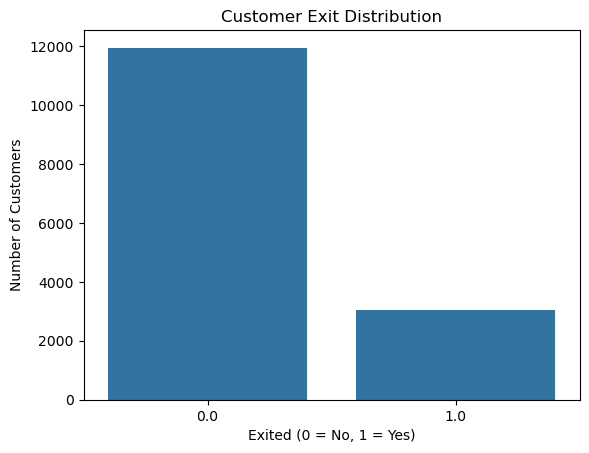

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=train_df, x='Exited')

plt.title('Customer Exit Distribution')
plt.xlabel('Exited (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')
plt.show()

In [26]:
train_df.groupby('Geography')['Exited'].value_counts()

Geography  Exited
France     0.0       7578
           1.0       1393
Germany    0.0       1571
           1.0       1137
Spain      0.0       2793
           1.0        528
Name: count, dtype: int64

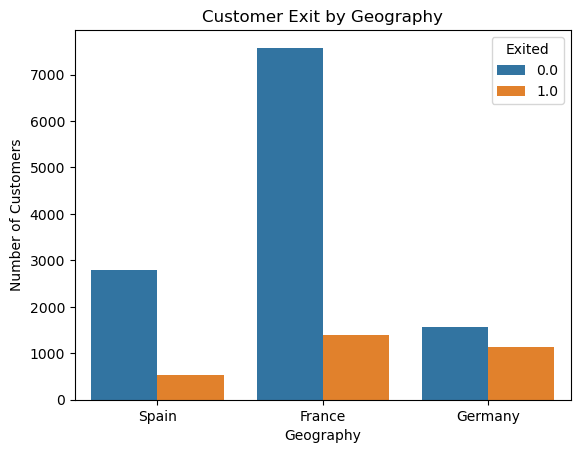

In [27]:
sns.countplot(data=train_df, x='Geography', hue='Exited')

plt.title('Customer Exit by Geography')
plt.xlabel('Geography')
plt.ylabel('Number of Customers')

plt.show()

In [28]:
train_df.groupby('Geography')['Exited'].mean() * 100

Geography
France     15.527812
Germany    41.986706
Spain      15.898826
Name: Exited, dtype: float64

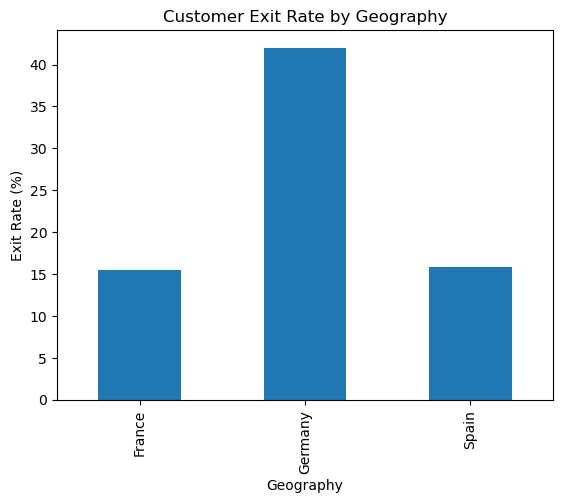

In [29]:
exit_rate_geo = train_df.groupby('Geography')['Exited'].mean() * 100

exit_rate_geo.plot(kind='bar')

plt.title('Customer Exit Rate by Geography')
plt.xlabel('Geography')
plt.ylabel('Exit Rate (%)')

plt.show()

In [30]:
geo_analysis = train_df.groupby('Geography').agg(
    Total_Customers=('Exited', 'count'),
    Exited_Customers=('Exited', 'sum'),
    Exit_Rate=('Exited', 'mean')
)

geo_analysis['Exit_Rate'] = geo_analysis['Exit_Rate'] * 100

geo_analysis

,Total_Customers,Exited_Customers,Exit_Rate
Geography,,,
France,8971,1393.0,15.527812
Germany,2708,1137.0,41.986706
Spain,3321,528.0,15.898826


In [31]:
train_df.groupby('Gender')['Exited'].value_counts();

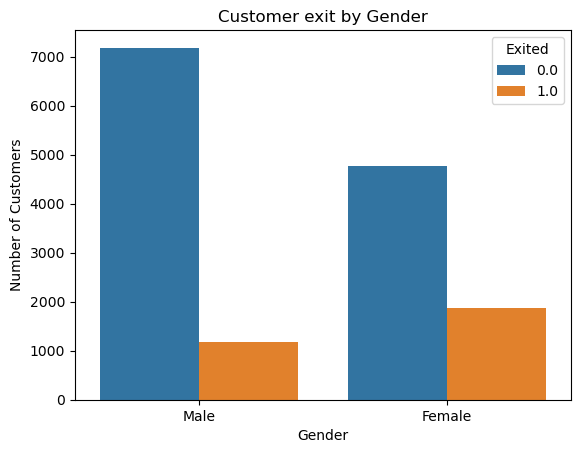

In [32]:
sns.countplot(data = train_df, x = 'Gender', hue = 'Exited')
plt.title('Customer exit by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

plt.show()

In [33]:
train_df.groupby('Gender')['Exited'].mean()*100

Gender
Female    28.304727
Male      14.094281
Name: Exited, dtype: float64

In [34]:
exit_rate_gender = train_df.groupby('Gender')['Exited'].mean()*100

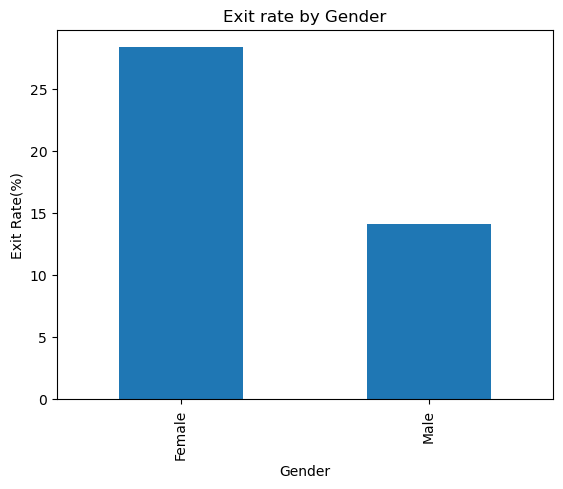

In [35]:
exit_rate_gender.plot(kind = 'bar')

plt.title('Exit rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Exit Rate(%)')

plt.show()

In [36]:
gender_analysis = train_df.groupby('Gender').agg(
    Total_Customers=('Exited', 'count'),
    Exited_Customers=('Exited', 'sum'),
    Exit_Rate=('Exited', 'mean')
)

gender_analysis['Exit_Rate'] = gender_analysis['Exit_Rate'] * 100

gender_analysis

,Total_Customers,Exited_Customers,Exit_Rate
Gender,,,
Female,6642,1880.0,28.304727
Male,8358,1178.0,14.094281


In [37]:
train_df['Age'].describe()

count    15000.000000
mean        37.888000
std          8.257409
min         18.000000
25%         32.000000
50%         37.000000
75%         42.000000
max         74.000000
Name: Age, dtype: float64

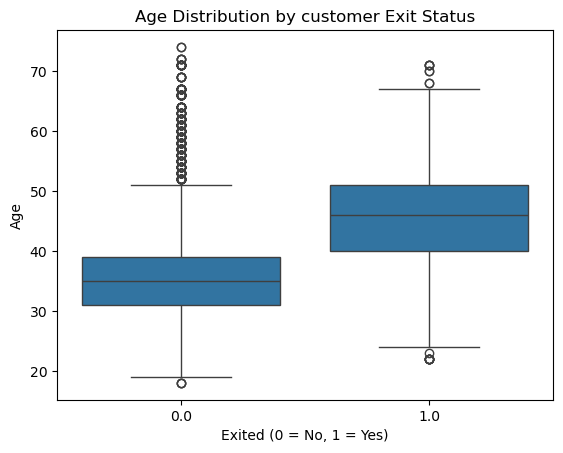

In [38]:
sns.boxplot(data = train_df, x = 'Exited', y = 'Age')

plt.title("Age Distribution by customer Exit Status")
plt.xlabel('Exited (0 = No, 1 = Yes)')
plt.ylabel('Age')
plt.show()

In [39]:
train_df.groupby('Exited')['Age'].describe()

,count,mean,std,min,25%,50%,75%,max
Exited,,,,,,,,
0.0,11942.0,35.876654,7.028835,18.0,31.0,35.0,39.0,74.0
1.0,3058.0,45.742642,8.002871,22.0,40.0,46.0,51.0,71.0


In [40]:
train_df['AgeGroup'] = pd.cut(
    train_df['Age'],
    bins=[17, 25, 35, 45, 55, 65, 75],
    labels=['18-25', '26-35', '36-45', '46-55', '56-65', '66-75']
)

In [41]:
train_df.groupby('AgeGroup', observed=True)['Exited'].mean() * 100

AgeGroup
18-25     3.393214
26-35     4.864407
36-45    19.177860
46-55    66.923925
56-65    66.081871
66-75    17.204301
Name: Exited, dtype: float64

In [42]:
train_df['AgeGroup'].value_counts().sort_index()

AgeGroup
18-25     501
26-35    5900
36-45    6179
46-55    1814
56-65     513
66-75      93
Name: count, dtype: int64

In [43]:
age_analysis = train_df.groupby('AgeGroup', observed=True).agg(
    Total_Customers=('Exited', 'count'),
    Exited_Customers=('Exited', 'sum'),
    Exit_Rate=('Exited', 'mean')
)

age_analysis['Exit_Rate'] = age_analysis['Exit_Rate'] * 100

age_analysis

,Total_Customers,Exited_Customers,Exit_Rate
AgeGroup,,,
18-25,501,17.0,3.393214
26-35,5900,287.0,4.864407
36-45,6179,1185.0,19.177860
46-55,1814,1214.0,66.923925
56-65,513,339.0,66.081871
66-75,93,16.0,17.204301


In [44]:
train_df['Tenure'].describe()

count    15000.000000
mean         5.033333
std          2.808359
min          0.000000
25%          3.000000
50%          5.000000
75%          7.000000
max         10.000000
Name: Tenure, dtype: float64

In [45]:
train_df['Tenure'].value_counts().sort_index()

Tenure
0.0      446
1.0     1533
2.0     1585
3.0     1553
4.0     1605
5.0     1556
6.0     1455
7.0     1568
8.0     1586
9.0     1586
10.0     527
Name: count, dtype: int64

In [46]:
train_df.groupby('Tenure')['Exited'].value_counts()

Tenure  Exited
0.0     0.0        322
        1.0        124
1.0     0.0       1181
        1.0        352
2.0     0.0       1286
        1.0        299
3.0     0.0       1226
        1.0        327
4.0     0.0       1294
        1.0        311
5.0     0.0       1249
        1.0        307
6.0     0.0       1162
        1.0        293
7.0     0.0       1298
        1.0        270
8.0     0.0       1281
        1.0        305
9.0     0.0       1225
        1.0        361
10.0    0.0        418
        1.0        109
Name: count, dtype: int64

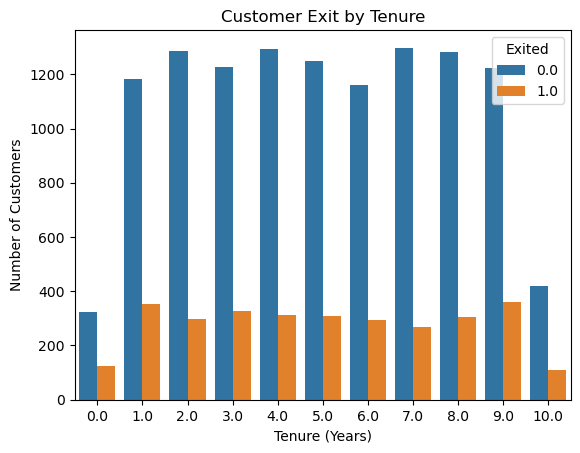

In [47]:
sns.countplot(data=train_df, x='Tenure', hue='Exited')

plt.title('Customer Exit by Tenure')
plt.xlabel('Tenure (Years)')
plt.ylabel('Number of Customers')

plt.show()

In [48]:
train_df.groupby('Tenure')['Exited'].mean() * 100

Tenure
0.0     27.802691
1.0     22.961513
2.0     18.864353
3.0     21.056021
4.0     19.376947
5.0     19.730077
6.0     20.137457
7.0     17.219388
8.0     19.230769
9.0     22.761665
10.0    20.683112
Name: Exited, dtype: float64

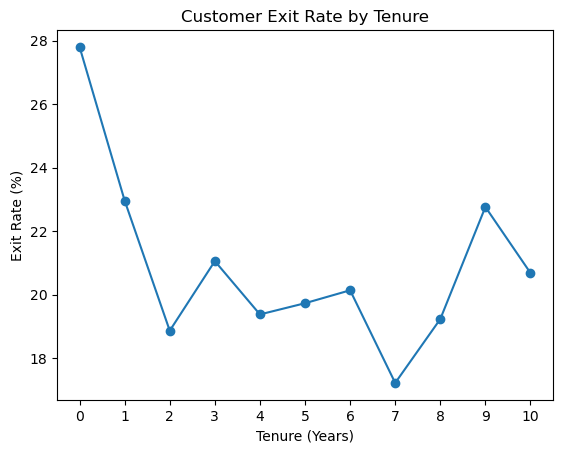

In [49]:
exit_rate_tenure = train_df.groupby('Tenure')['Exited'].mean() * 100

plt.plot(exit_rate_tenure.index, exit_rate_tenure.values, marker='o')

plt.title('Customer Exit Rate by Tenure')
plt.xlabel('Tenure (Years)')
plt.ylabel('Exit Rate (%)')
plt.xticks(range(0, 11))

plt.show()

In [50]:
train_df['Tenure'].value_counts().sort_index()

Tenure
0.0      446
1.0     1533
2.0     1585
3.0     1553
4.0     1605
5.0     1556
6.0     1455
7.0     1568
8.0     1586
9.0     1586
10.0     527
Name: count, dtype: int64

In [51]:
train_df['Balance'].describe()

count     15000.000000
mean      43124.060479
std       59777.868496
min           0.000000
25%           0.000000
50%           0.000000
75%      109650.982500
max      187530.660000
Name: Balance, dtype: float64

In [52]:
(train_df['Balance'] == 0).sum()

np.int64(9684)

In [53]:
(train_df['Balance'] == 0).mean() * 100

np.float64(64.56)

In [54]:
balance_status = train_df.groupby(
    train_df['Balance'] == 0
)['Exited'].mean() * 100

balance_status

Balance
False    28.799850
True     15.768278
Name: Exited, dtype: float64

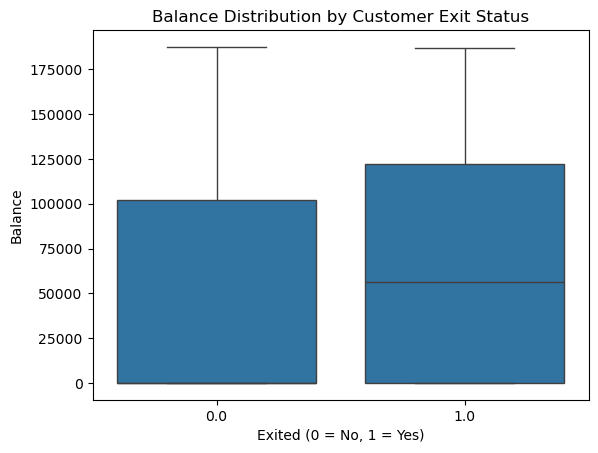

In [55]:
sns.boxplot(data=train_df, x='Exited', y='Balance')

plt.title('Balance Distribution by Customer Exit Status')
plt.xlabel('Exited (0 = No, 1 = Yes)')
plt.ylabel('Balance')

plt.show()

In [56]:
train_df.groupby('Exited')['Balance'].describe()

,count,mean,std,min,25%,50%,75%,max
Exited,,,,,,,,
0.0,11942.0,38427.402345,57959.622295,0.0,0.0,0.00,102044.3225,187530.66
1.0,3058.0,61465.293780,63151.293351,0.0,0.0,56580.93,122434.5925,186788.96


In [58]:
positive_balance_df = train_df[train_df['Balance'] > 0]

In [59]:
positive_balance_df.groupby('Exited')['Balance'].describe()

,count,mean,std,min,25%,50%,75%,max
Exited,,,,,,,,
0.0,3785.0,121241.753977,23614.375026,753.37,104784.23,122793.96,137780.74,187530.66
1.0,1531.0,122769.998942,20905.839808,55732.92,109410.33,122398.54,135068.80,186788.96


In [61]:
train_df['BalanceGroup'] = pd.cut(
    train_df['Balance'],
    bins=[-1, 0, 50000, 100000, 150000, float('inf')],
    labels=['0', '1-50K', '50-100K', '100-150K', '150K+']
)

In [62]:
balance_exit_rate = train_df.groupby(
    'BalanceGroup',
    observed=True
)['Exited'].mean() * 100

balance_exit_rate

BalanceGroup
0           15.768278
1-50K        0.000000
50-100K     18.763797
100-150K    31.478126
150K+       26.605505
Name: Exited, dtype: float64

In [63]:
train_df['BalanceGroup'].value_counts().sort_index()

BalanceGroup
0           9684
1-50K          2
50-100K      906
100-150K    3863
150K+        545
Name: count, dtype: int64

NumOfProducts
1.0    6437
2.0    8305
3.0     218
4.0      40
Name: count, dtype: int64
NumOfProducts
1.0    38.076744
2.0     4.334738
3.0    95.412844
4.0    97.500000
Name: Exited, dtype: float64


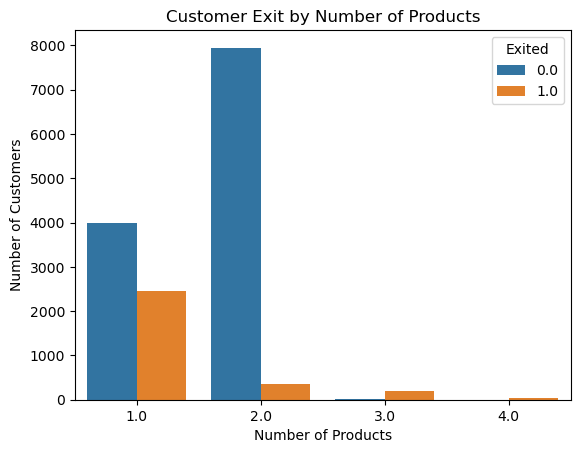

In [64]:
# Distribution
print(train_df['NumOfProducts'].value_counts().sort_index())

# Exit rate
print(
    train_df.groupby('NumOfProducts')['Exited'].mean() * 100
)

# Visualization
sns.countplot(data=train_df, x='NumOfProducts', hue='Exited')

plt.title('Customer Exit by Number of Products')
plt.xlabel('Number of Products')
plt.ylabel('Number of Customers')
plt.show()

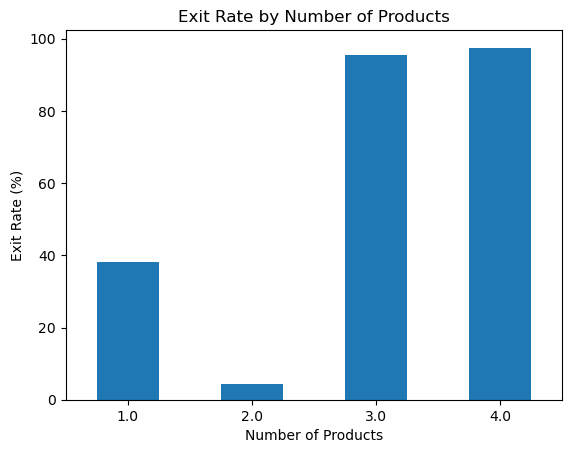

In [65]:
product_exit_rate = train_df.groupby('NumOfProducts')['Exited'].mean() * 100

product_exit_rate.plot(kind='bar')

plt.title('Exit Rate by Number of Products')
plt.xlabel('Number of Products')
plt.ylabel('Exit Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [66]:
print("Customer count:")
print(train_df['NumOfProducts'].value_counts().sort_index())

print("\nExit rate:")
print(train_df.groupby('NumOfProducts')['Exited'].mean() * 100)

Customer count:
NumOfProducts
1.0    6437
2.0    8305
3.0     218
4.0      40
Name: count, dtype: int64

Exit rate:
NumOfProducts
1.0    38.076744
2.0     4.334738
3.0    95.412844
4.0    97.500000
Name: Exited, dtype: float64


In [67]:
print("Customer count:")
print(train_df['HasCrCard'].value_counts().sort_index())

print("\nExit rate:")
print(train_df.groupby('HasCrCard')['Exited'].mean() * 100)

Customer count:
HasCrCard
0.0     3252
1.0    11748
Name: count, dtype: int64

Exit rate:
HasCrCard
0.0    22.539975
1.0    19.790603
Name: Exited, dtype: float64


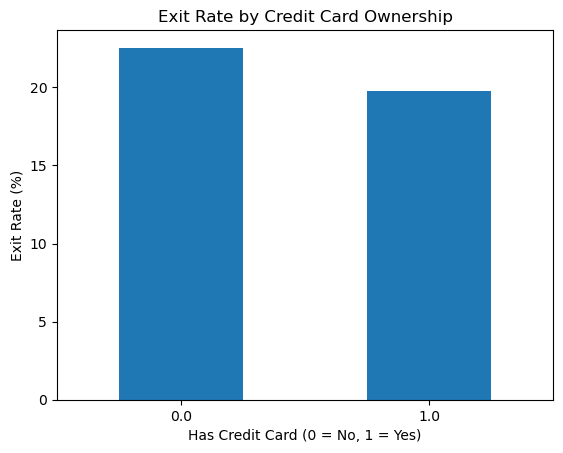

In [68]:
card_exit_rate = train_df.groupby('HasCrCard')['Exited'].mean() * 100

card_exit_rate.plot(kind='bar')

plt.title('Exit Rate by Credit Card Ownership')
plt.xlabel('Has Credit Card (0 = No, 1 = Yes)')
plt.ylabel('Exit Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [69]:
print("Customer count:")
print(train_df['IsActiveMember'].value_counts().sort_index())

print("\nExit rate:")
print(train_df.groupby('IsActiveMember')['Exited'].mean() * 100)

Customer count:
IsActiveMember
0.0    7497
1.0    7503
Name: count, dtype: int64

Exit rate:
IsActiveMember
0.0    28.678138
1.0    12.101826
Name: Exited, dtype: float64


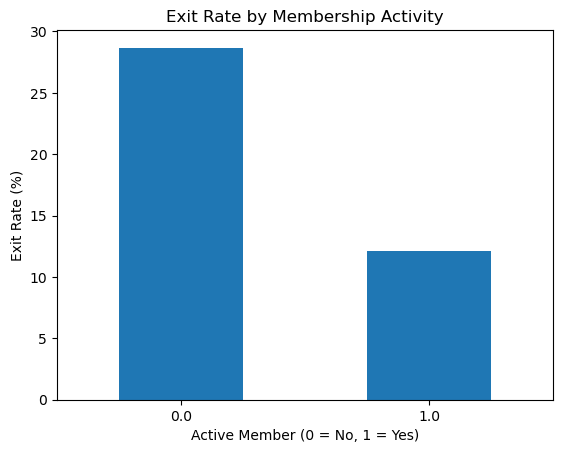

In [70]:
active_exit_rate = train_df.groupby('IsActiveMember')['Exited'].mean() * 100

active_exit_rate.plot(kind='bar')

plt.title('Exit Rate by Membership Activity')
plt.xlabel('Active Member (0 = No, 1 = Yes)')
plt.ylabel('Exit Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [71]:
train_df.groupby('Exited')['CreditScore'].describe()

,count,mean,std,min,25%,50%,75%,max
Exited,,,,,,,,
0.0,11942.0,660.519176,72.111132,431.0,604.00,663.0,710.0,850.0
1.0,3058.0,652.338784,74.069465,445.0,594.25,652.0,705.0,850.0


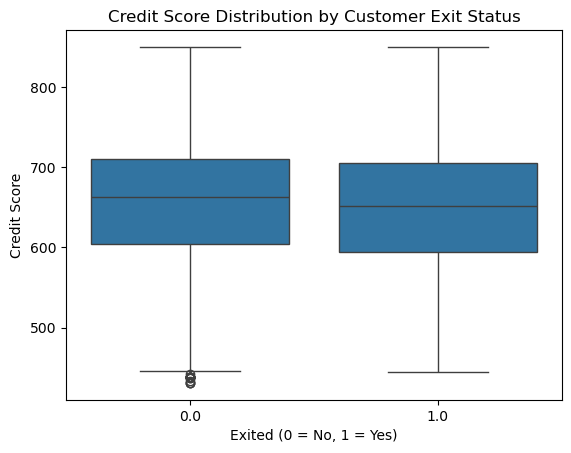

In [72]:
sns.boxplot(data=train_df, x='Exited', y='CreditScore')

plt.title('Credit Score Distribution by Customer Exit Status')
plt.xlabel('Exited (0 = No, 1 = Yes)')
plt.ylabel('Credit Score')
plt.show()

In [73]:
train_df.groupby('Exited')['EstimatedSalary'].describe()

,count,mean,std,min,25%,50%,75%,max
Exited,,,,,,,,
0.0,11942.0,117578.002658,46976.218404,11.58,83612.8800,122580.48,155711.6400,1557802.42
1.0,3058.0,120309.327541,46064.048169,479.54,84511.8875,126421.54,161351.9125,199992.48


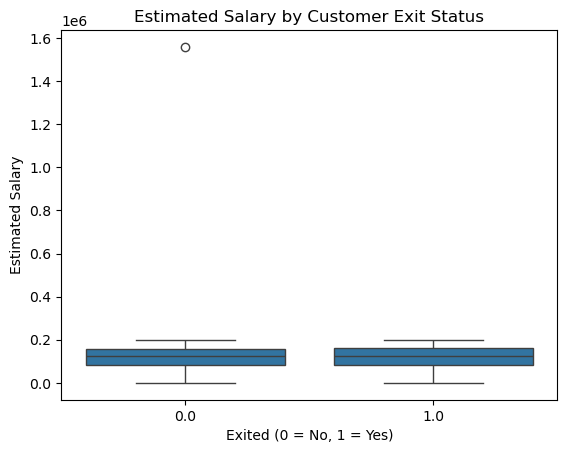

In [74]:
sns.boxplot(data=train_df, x='Exited', y='EstimatedSalary')

plt.title('Estimated Salary by Customer Exit Status')
plt.xlabel('Exited (0 = No, 1 = Yes)')
plt.ylabel('Estimated Salary')
plt.show()

In [75]:
numeric_cols = [
    'CreditScore',
    'Age',
    'Tenure',
    'Balance',
    'NumOfProducts',
    'HasCrCard',
    'IsActiveMember',
    'EstimatedSalary',
    'Exited'
]

correlation_matrix = train_df[numeric_cols].corr()

correlation_matrix

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
CreditScore,1.000000,-0.028554,0.010880,-0.001484,0.013253,0.001712,0.005532,-0.005020,-0.045404
Age,-0.028554,1.000000,-0.004042,0.077698,-0.156067,-0.000161,-0.054218,0.008223,0.481368
Tenure,0.010880,-0.004042,1.000000,-0.007729,0.005968,0.009932,-0.016385,0.007373,-0.015022
Balance,-0.001484,0.077698,-0.007729,1.000000,-0.411900,-0.003137,-0.022923,0.013130,0.155268
NumOfProducts,0.013253,-0.156067,0.005968,-0.411900,1.000000,0.019957,0.052711,0.008717,-0.282240
HasCrCard,0.001712,-0.000161,0.009932,-0.003137,0.019957,1.000000,-0.018233,-0.021298,-0.028121
IsActiveMember,0.005532,-0.054218,-0.016385,-0.022923,0.052711,-0.018233,1.000000,-0.002575,-0.205727
EstimatedSalary,-0.005020,0.008223,0.007373,0.013130,0.008717,-0.021298,-0.002575,1.000000,0.023511
Exited,-0.045404,0.481368,-0.015022,0.155268,-0.282240,-0.028121,-0.205727,0.023511,1.000000


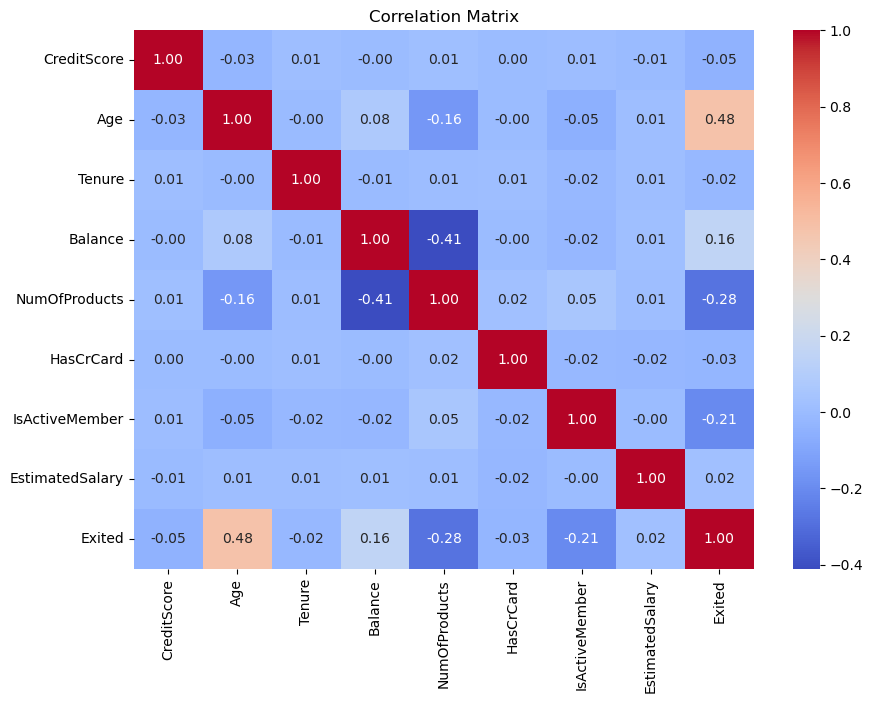

In [76]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Correlation Matrix')
plt.show()

## Data Preprocessing

In [77]:
X = train_df.drop(columns=['Exited'])
y = train_df['Exited']

In [78]:
X = X.drop(columns=['id', 'CustomerId', 'Surname'])

In [79]:
X.columns

Index(['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
       'AgeGroup', 'BalanceGroup'],
      dtype='object')

In [80]:
X = X.drop(columns=['AgeGroup', 'BalanceGroup'])


In [81]:
X.columns

Index(['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary'],
      dtype='object')

## Encoding

In [82]:
X = pd.get_dummies(
    X,
    columns=['Geography', 'Gender'],
    drop_first=True,
    dtype=int
)

In [83]:
X.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,754.0,40.0,8.0,102954.68,2.0,1.0,1.0,149238.35,0,1,1
1,579.0,28.0,1.0,0.00,2.0,1.0,0.0,64869.32,0,0,0
2,744.0,56.0,5.0,0.00,1.0,1.0,0.0,158816.03,0,0,0
3,697.0,29.0,2.0,0.00,2.0,1.0,0.0,55775.72,0,0,1
4,628.0,22.0,9.0,0.00,2.0,1.0,0.0,49653.39,0,0,0


### Train Test Split


In [84]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [85]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (12000, 11)
X_test : (3000, 11)
y_train: (12000,)
y_test : (3000,)


In [86]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution:
Exited
0.0    79.616667
1.0    20.383333
Name: proportion, dtype: float64

Testing target distribution:
Exited
0.0    79.6
1.0    20.4
Name: proportion, dtype: float64


### Feature Scaling

In [87]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [88]:
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (12000, 11)
X_test_scaled shape: (3000, 11)


In [89]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(random_state=42)

logistic_model.fit(X_train_scaled, y_train)

LogisticRegression(random_state=42)

In [90]:
y_pred_logistic = logistic_model.predict(X_test_scaled)

In [91]:
print(y_pred_logistic[:20])

[1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 1. 1.]


In [92]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred_logistic)
precision = precision_score(y_test, y_pred_logistic)
recall = recall_score(y_test, y_pred_logistic)
f1 = f1_score(y_test, y_pred_logistic)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.867
Precision: 0.7371937639198218
Recall   : 0.5408496732026143
F1 Score : 0.6239396795475967


In [93]:
from sklearn.metrics import roc_auc_score

y_prob_logistic = logistic_model.predict_proba(X_test_scaled)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob_logistic)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.8825233192104311


In [94]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_logistic)

print(cm)

[[2270  118]
 [ 281  331]]


In [95]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(
    random_state=42
)

decision_tree.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [96]:
y_pred_tree = decision_tree.predict(X_test)

print(y_pred_tree[:20])

[1. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 1. 1. 0. 1. 0. 1. 0. 1. 0.]


In [97]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_tree = accuracy_score(y_test, y_pred_tree)
precision_tree = precision_score(y_test, y_pred_tree)
recall_tree = recall_score(y_test, y_pred_tree)
f1_tree = f1_score(y_test, y_pred_tree)

print("Accuracy :", accuracy_tree)
print("Precision:", precision_tree)
print("Recall   :", recall_tree)
print("F1 Score :", f1_tree)

Accuracy : 0.8503333333333334
Precision: 0.6304
Recall   : 0.6437908496732027
F1 Score : 0.6370250606305577


In [98]:
from sklearn.metrics import roc_auc_score

y_prob_tree = decision_tree.predict_proba(X_test)[:, 1]

roc_auc_tree = roc_auc_score(y_test, y_prob_tree)

print("ROC-AUC:", roc_auc_tree)

ROC-AUC: 0.773528590665747


In [99]:
from sklearn.metrics import confusion_matrix

cm_tree = confusion_matrix(y_test, y_pred_tree)

print(cm_tree)

[[2157  231]
 [ 218  394]]


In [100]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

random_forest.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

In [101]:
y_pred_rf = random_forest.predict(X_test)

print(y_pred_rf[:20])

[1. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 1. 0. 1. 0. 1. 0. 1. 1.]


In [102]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("Accuracy :", accuracy_rf)
print("Precision:", precision_rf)
print("Recall   :", recall_rf)
print("F1 Score :", f1_rf)

Accuracy : 0.891
Precision: 0.7833001988071571
Recall   : 0.6437908496732027
F1 Score : 0.7067264573991031


In [103]:
from sklearn.metrics import roc_auc_score

y_prob_rf = random_forest.predict_proba(X_test)[:, 1]

roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("ROC-AUC:", roc_auc_rf)

ROC-AUC: 0.9265000109479861


In [104]:
from sklearn.metrics import confusion_matrix

cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)

[[2279  109]
 [ 218  394]]


In [106]:
!pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   - -------------------------------------- 1.3/48.9 MB 10.1 MB/s eta 0:00:05
   - -------------------------------------- 2.1/48.9 MB 5.9 MB/s eta 0:00:08
   -- ------------------------------------- 2.6/48.9 MB 4.7 MB/s eta 0:00:10
   -- ------------------------------------- 3.1/48.9 MB 4.3 MB/s eta 0:00:11
   -- ------------------------------------- 3.4/48.9 MB 3.9 MB/s eta 0:00:12
   -- ------------------------------------- 3.7/48.9 MB 3.4 MB/s eta 0:00:14
   --- ------------------------------------ 3.9/48.9 MB 2.9 MB/s eta 0:00:16
   --- ------------------------------------ 4.2/48.9 MB 2.7 MB/s eta 0:00:17
   --- ------------------------------------ 4.5/48.9 MB 2.5 MB/s eta 0:00:18
   --- ------------------------------------ 4.5/48.9 MB 2.5 MB/s eta 0:00:18
   --- ------------------------------------ 4.7/48.9 MB 2.1 MB/s eta 0:00:21
   ---- ----------------------------------- 5.0/48.9 MB 2.0 MB/s eta 0:00:22
   --

In [107]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

In [108]:
y_pred_xgb = xgb_model.predict(X_test)

print(y_pred_xgb[:20])

[1 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 1 0 1 1]


In [109]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)

print("Accuracy :", accuracy_xgb)
print("Precision:", precision_xgb)
print("Recall   :", recall_xgb)
print("F1 Score :", f1_xgb)

Accuracy : 0.898
Precision: 0.7965116279069767
Recall   : 0.6715686274509803
F1 Score : 0.7287234042553191


In [110]:
from sklearn.metrics import roc_auc_score

y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)

print("ROC-AUC:", roc_auc_xgb)

ROC-AUC: 0.9324858223579774


In [111]:
from sklearn.metrics import confusion_matrix

cm_xgb = confusion_matrix(y_test, y_pred_xgb)

print(cm_xgb)

[[2283  105]
 [ 201  411]]


In [112]:
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'XGBoost'
    ],
    'Accuracy': [
        accuracy,
        accuracy_tree,
        accuracy_rf,
        accuracy_xgb
    ],
    'Precision': [
        precision,
        precision_tree,
        precision_rf,
        precision_xgb
    ],
    'Recall': [
        recall,
        recall_tree,
        recall_rf,
        recall_xgb
    ],
    'F1 Score': [
        f1,
        f1_tree,
        f1_rf,
        f1_xgb
    ],
    'ROC-AUC': [
        roc_auc,
        roc_auc_tree,
        roc_auc_rf,
        roc_auc_xgb
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.867000,0.737194,0.540850,0.623940,0.882523
1,Decision Tree,0.850333,0.630400,0.643791,0.637025,0.773529
2,Random Forest,0.891000,0.783300,0.643791,0.706726,0.926500
3,XGBoost,0.898000,0.796512,0.671569,0.728723,0.932486


In [113]:
id="imbalance1"
from collections import Counter

class_counts = Counter(y_train)

print("Class counts:", class_counts)

scale_pos_weight = class_counts[0] / class_counts[1]

print("scale_pos_weight:", scale_pos_weight)

Class counts: Counter({0.0: 9554, 1.0: 2446})
scale_pos_weight: 3.9059689288634507


In [114]:
id="imbalance2"
xgb_balanced = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss'
)

xgb_balanced.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

In [115]:
id="imbalance3"
y_pred_xgb_balanced = xgb_balanced.predict(X_test)

print(y_pred_xgb_balanced[:20])

[1 0 0 0 0 0 1 0 1 0 0 1 1 0 1 0 1 0 1 1]


In [116]:
accuracy_xgb_balanced = accuracy_score(y_test, y_pred_xgb_balanced)
precision_xgb_balanced = precision_score(y_test, y_pred_xgb_balanced)
recall_xgb_balanced = recall_score(y_test, y_pred_xgb_balanced)
f1_xgb_balanced = f1_score(y_test, y_pred_xgb_balanced)

print("Accuracy :", accuracy_xgb_balanced)
print("Precision:", precision_xgb_balanced)
print("Recall   :", recall_xgb_balanced)
print("F1 Score :", f1_xgb_balanced)

Accuracy : 0.8633333333333333
Precision: 0.6237745098039216
Recall   : 0.8316993464052288
F1 Score : 0.7128851540616247


In [117]:
y_prob_xgb_balanced = xgb_balanced.predict_proba(X_test)[:, 1]

roc_auc_xgb_balanced = roc_auc_score(
    y_test,
    y_prob_xgb_balanced
)

print("ROC-AUC:", roc_auc_xgb_balanced)

ROC-AUC: 0.9320547454045829


In [118]:
cm_xgb_balanced = confusion_matrix(
    y_test,
    y_pred_xgb_balanced
)

print(cm_xgb_balanced)

[[2081  307]
 [ 103  509]]


In [119]:
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob_xgb >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_test, y_pred_threshold),
        'Recall': recall_score(y_test, y_pred_threshold),
        'F1 Score': f1_score(y_test, y_pred_threshold)
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,Threshold,Precision,Recall,F1 Score
0,0.30,0.693410,0.790850,0.738931
1,0.35,0.715611,0.756536,0.735504
2,0.40,0.745424,0.732026,0.738664
3,0.45,0.766071,0.700980,0.732082
4,0.50,0.796512,0.671569,0.728723
5,0.55,0.812109,0.635621,0.713107
6,0.60,0.825893,0.604575,0.698113


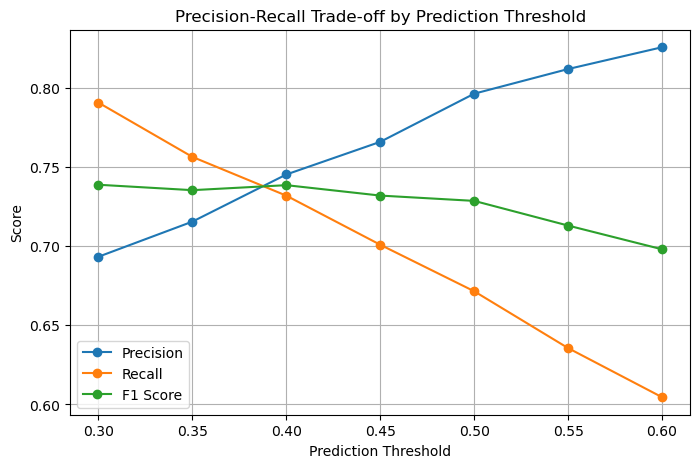

In [120]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['F1 Score'],
    marker='o',
    label='F1 Score'
)

plt.xlabel('Prediction Threshold')
plt.ylabel('Score')
plt.title('Precision-Recall Trade-off by Prediction Threshold')
plt.legend()
plt.grid(True)

plt.show()

In [121]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

xgb_tuning = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

param_grid = {
    'n_estimators': [100, 200, 300, 400],
    'max_depth': [3, 4, 5, 6, 7],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0]
}

In [122]:
random_search = RandomizedSearchCV(
    estimator=xgb_tuning,
    param_distributions=param_grid,
    n_iter=20,
    scoring='roc_auc',
    cv=5,
    random_state=42,
    n_jobs=-1
)

In [123]:
random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=5,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=True,
                                           eval_metric='logloss',
                                           feature_types=None,
                                           feature_weights=None, gamma=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_const...
                                           min_child_weight=None, missing=nan,
                                           monotone_constraints=None,
                                           multi_strategy=None,
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None, ...),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.7, 0.8, 0.9,
                                                             1.0],
                                        'learning_rate': [0.01, 0.03, 0.05,
                                                          0.1],
                                        'max_depth': [3, 4, 5, 6, 7],
                                        'n_estimators': [100, 200, 300, 400],
                                        'subsample': [0.7, 0.8, 0.9, 1.0]},
                   random_state=42, scoring='roc_auc')

In [124]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(random_search.best_score_)

Best Parameters:
{'subsample': 0.8, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.8}

Best Cross-Validation ROC-AUC:
0.9357769932826303


In [125]:
random_search.best_estimator_

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.03, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

In [126]:
tuned_xgb = random_search.best_estimator_

In [127]:
y_pred_tuned = tuned_xgb.predict(X_test)

y_prob_tuned = tuned_xgb.predict_proba(X_test)[:, 1]

In [128]:
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned)
recall_tuned = recall_score(y_test, y_pred_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned)
roc_auc_tuned = roc_auc_score(y_test, y_prob_tuned)

print("Accuracy :", accuracy_tuned)
print("Precision:", precision_tuned)
print("Recall   :", recall_tuned)
print("F1 Score :", f1_tuned)
print("ROC-AUC  :", roc_auc_tuned)

Accuracy : 0.8986666666666666
Precision: 0.8043478260869565
Recall   : 0.6650326797385621
F1 Score : 0.7280858676207513
ROC-AUC  : 0.9337622891144175


In [129]:
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

print("Confusion Matrix:")
print(cm_tuned)

Confusion Matrix:
[[2289   99]
 [ 205  407]]


In [130]:
print(X.columns.tolist())
print(X.shape)

['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']
(15000, 11)


In [131]:
print(X_train.shape)
print(X_test.shape)

(12000, 11)
(3000, 11)


In [132]:
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

X_train_fe['IsZeroBalance'] = (X_train_fe['Balance'] == 0).astype(int)
X_test_fe['IsZeroBalance'] = (X_test_fe['Balance'] == 0).astype(int)

In [133]:
X_train_fe['BalancePerProduct'] = (
    X_train_fe['Balance'] / X_train_fe['NumOfProducts']
)

X_test_fe['BalancePerProduct'] = (
    X_test_fe['Balance'] / X_test_fe['NumOfProducts']
)

In [134]:
X_train_fe['AgeSquared'] = X_train_fe['Age'] ** 2
X_test_fe['AgeSquared'] = X_test_fe['Age'] ** 2

In [135]:
X_train_fe['ActiveProductInteraction'] = (
    X_train_fe['IsActiveMember'] * X_train_fe['NumOfProducts']
)

X_test_fe['ActiveProductInteraction'] = (
    X_test_fe['IsActiveMember'] * X_test_fe['NumOfProducts']
)

In [136]:
X_train_fe['AgeActivityInteraction'] = (
    X_train_fe['Age'] * X_train_fe['IsActiveMember']
)

X_test_fe['AgeActivityInteraction'] = (
    X_test_fe['Age'] * X_test_fe['IsActiveMember']
)

In [137]:
print("Original features:", X_train.shape[1])
print("Engineered features:", X_train_fe.shape[1])

print(X_train_fe.columns.tolist())

Original features: 11
Engineered features: 16
['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male', 'IsZeroBalance', 'BalancePerProduct', 'AgeSquared', 'ActiveProductInteraction', 'AgeActivityInteraction']


In [138]:
xgb_fe = XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss'
)

xgb_fe.fit(X_train_fe, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.03, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

In [139]:
y_pred_fe = xgb_fe.predict(X_test_fe)
y_prob_fe = xgb_fe.predict_proba(X_test_fe)[:, 1]

In [140]:
accuracy_fe = accuracy_score(y_test, y_pred_fe)
precision_fe = precision_score(y_test, y_pred_fe)
recall_fe = recall_score(y_test, y_pred_fe)
f1_fe = f1_score(y_test, y_pred_fe)
roc_auc_fe = roc_auc_score(y_test, y_prob_fe)

print("Accuracy :", accuracy_fe)
print("Precision:", precision_fe)
print("Recall   :", recall_fe)
print("F1 Score :", f1_fe)
print("ROC-AUC  :", roc_auc_fe)

Accuracy : 0.899
Precision: 0.8047337278106509
Recall   : 0.6666666666666666
F1 Score : 0.7292225201072386
ROC-AUC  : 0.9334796942227478


In [141]:
thresholds = [0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

threshold_results_tuned = []

for threshold in thresholds:
    y_pred_threshold = (y_prob_fe >= threshold).astype(int)

    threshold_results_tuned.append({
        'Threshold': threshold,
        'Precision': precision_score(y_test, y_pred_threshold),
        'Recall': recall_score(y_test, y_pred_threshold),
        'F1 Score': f1_score(y_test, y_pred_threshold)
    })

threshold_df_tuned = pd.DataFrame(threshold_results_tuned)

threshold_df_tuned

,Threshold,Precision,Recall,F1 Score
0,0.25,0.653141,0.815359,0.725291
1,0.30,0.691751,0.781046,0.733691
2,0.35,0.720635,0.741830,0.731079
3,0.40,0.761905,0.705882,0.732824
4,0.45,0.778598,0.689542,0.731369
5,0.50,0.804734,0.666667,0.729223
6,0.55,0.824561,0.614379,0.704120
7,0.60,0.837321,0.571895,0.679612


In [142]:
feature_importance = pd.DataFrame({
    'Feature': X_train_fe.columns,
    'Importance': xgb_fe.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance

,Feature,Importance
13,AgeSquared,0.245294
1,Age,0.200387
4,NumOfProducts,0.110213
14,ActiveProductInteraction,0.087354
8,Geography_Germany,0.075560
6,IsActiveMember,0.053753
10,Gender_Male,0.048441
11,IsZeroBalance,0.044805
12,BalancePerProduct,0.035670
15,AgeActivityInteraction,0.030573


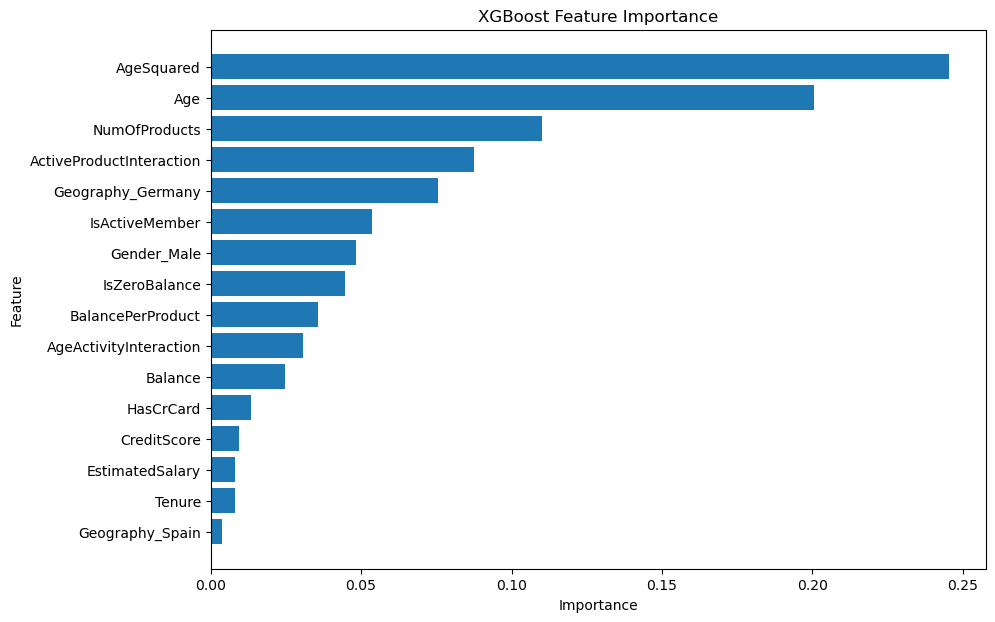

In [143]:
plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('XGBoost Feature Importance')

plt.gca().invert_yaxis()
plt.show()

In [146]:
!pip install shap


   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]



In [147]:
import shap

explainer = shap.TreeExplainer(xgb_fe)

shap_values = explainer.shap_values(X_test_fe)

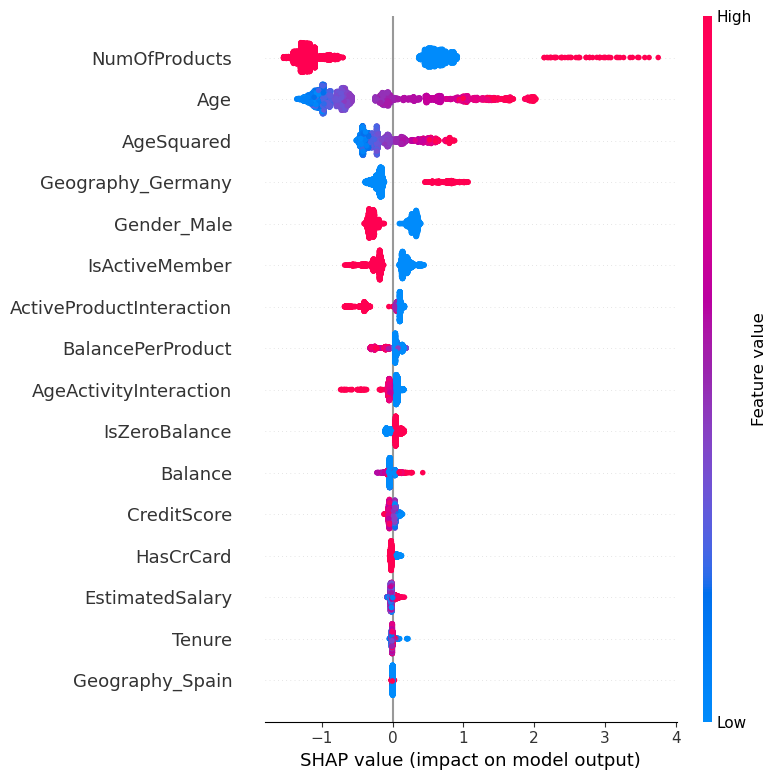

In [148]:
shap.summary_plot(
    shap_values,
    X_test_fe,
    feature_names=X_test_fe.columns
)

In [149]:
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'XGBoost',
        'Balanced XGBoost',
        'Tuned XGBoost',
        'Feature Engineered XGBoost'
    ],
    'Accuracy': [
        accuracy,
        accuracy_tree,
        accuracy_rf,
        accuracy_xgb,
        accuracy_xgb_balanced,
        accuracy_tuned,
        accuracy_fe
    ],
    'Precision': [
        precision,
        precision_tree,
        precision_rf,
        precision_xgb,
        precision_xgb_balanced,
        precision_tuned,
        precision_fe
    ],
    'Recall': [
        recall,
        recall_tree,
        recall_rf,
        recall_xgb,
        recall_xgb_balanced,
        recall_tuned,
        recall_fe
    ],
    'F1 Score': [
        f1,
        f1_tree,
        f1_rf,
        f1_xgb,
        f1_xgb_balanced,
        f1_tuned,
        f1_fe
    ],
    'ROC-AUC': [
        roc_auc,
        roc_auc_tree,
        roc_auc_rf,
        roc_auc_xgb,
        roc_auc_xgb_balanced,
        roc_auc_tuned,
        roc_auc_fe
    ]
})

model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8670,0.7372,0.5408,0.6239,0.8825
1,Decision Tree,0.8503,0.6304,0.6438,0.6370,0.7735
2,Random Forest,0.8910,0.7833,0.6438,0.7067,0.9265
3,XGBoost,0.8980,0.7965,0.6716,0.7287,0.9325
4,Balanced XGBoost,0.8633,0.6238,0.8317,0.7129,0.9321
5,Tuned XGBoost,0.8987,0.8043,0.6650,0.7281,0.9338
6,Feature Engineered XGBoost,0.8990,0.8047,0.6667,0.7292,0.9335


In [150]:
model_comparison.style.highlight_max(
    subset=['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC'],
    axis=0
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.867000,0.737194,0.540850,0.623940,0.882523
1,Decision Tree,0.850333,0.630400,0.643791,0.637025,0.773529
2,Random Forest,0.891000,0.783300,0.643791,0.706726,0.926500
3,XGBoost,0.898000,0.796512,0.671569,0.728723,0.932486
4,Balanced XGBoost,0.863333,0.623775,0.831699,0.712885,0.932055
5,Tuned XGBoost,0.898667,0.804348,0.665033,0.728086,0.933762
6,Feature Engineered XGBoost,0.899000,0.804734,0.666667,0.729223,0.933480


## Final Insights

### Key Findings

1. **Age is the strongest predictive factor**
   - Age and AgeSquared were among the most influential features in the final XGBoost model.
   - Higher age values generally contributed toward higher predicted exit risk.

2. **Number of products has a strong nonlinear relationship with exit**
   - Customers with different numbers of products showed substantially different observed exit rates.
   - The relationship was not simply linear, so product count should be interpreted carefully.

3. **Customer activity is an important indicator**
   - In the EDA, inactive members had a considerably higher observed exit rate than active members.
   - SHAP analysis also showed that being an active member generally pushed predictions toward lower exit risk.

4. **Geography contributes to prediction**
   - Germany showed a substantially higher observed exit rate than France and Spain in the dataset.
   - `Geography_Germany` was also one of the more influential features in the XGBoost model.

5. **Balance-related characteristics provide useful information**
   - Customers with positive balances had a higher observed exit rate than customers with zero balances.
   - Engineered features such as `IsZeroBalance` and `BalancePerProduct` also contributed to the model.

6. **Some variables have relatively weak standalone relationships**
   - Credit score, estimated salary, tenure, and credit-card ownership showed weaker individual relationships with the target compared with age, product count, activity, and geography.

7. **Model performance**
   - The final Feature-Engineered XGBoost model achieved approximately 89.9% accuracy, 80.5% precision, 66.7% recall, 72.9% F1-score, and 93.3% ROC-AUC on the held-out test set.

8. **Model explainability**
   - SHAP analysis was used to understand how individual features influenced the model's predictions.
   - These relationships represent model associations and should not be interpreted as proof of causation.

## Final Model

The Feature-Engineered XGBoost classifier was selected as the final model for the project.

The model incorporates the original customer attributes along with engineered features designed to capture nonlinear relationships and interactions between customer characteristics.

### Final Test Performance

- **Accuracy:** 89.90%
- **Precision:** 80.47%
- **Recall:** 66.67%
- **F1 Score:** 72.92%
- **ROC-AUC:** 93.33%

The model demonstrates strong ability to distinguish between customers who are likely to remain and customers who are likely to exit. Since the target variable is imbalanced, ROC-AUC, precision, recall and F1-score were considered alongside accuracy.

## Conclusion

This project developed a customer exit prediction system using Python-based data analysis and machine learning techniques.

The analysis began with data understanding and exploratory analysis to identify patterns in customer demographics, account characteristics, activity, product usage and financial attributes. Multiple classification algorithms were then developed and evaluated, including Logistic Regression, Decision Tree, Random Forest and XGBoost.

XGBoost-based models demonstrated stronger predictive performance than the simpler baseline models. Hyperparameter tuning, feature engineering and prediction-threshold analysis were subsequently performed to improve and understand the model.

The final Feature-Engineered XGBoost model achieved approximately 89.9% accuracy and a ROC-AUC of 93.3% on the held-out test dataset. SHAP explainability was also incorporated to understand the contribution of individual features to model predictions.

The resulting analysis demonstrates how customer data can be transformed into actionable predictive insights and provides a foundation for developing a production-level customer retention and exit-risk analysis application.

## Future Enhancements

- Develop an interactive Streamlit dashboard for customer analysis and prediction.
- Integrate the trained model with a FastAPI backend.
- Store customer, account and prediction information using PostgreSQL.
- Add authentication and role-based access for production deployment.
- Implement model monitoring and performance tracking.
- Use MLflow for experiment and model management.
- Use SHAP-based explanations within the prediction interface.
- Add customer feedback data and explore NLP-based sentiment analysis as a future extension.
- Deploy the complete system using Docker and a cloud platform.

In [153]:
import joblib

In [154]:
joblib.dump(xgb_fe, "final_xgboost_model.pkl")

['final_xgboost_model.pkl']

In [155]:
import os

print(os.path.exists("final_xgboost_model.pkl"))

True


In [156]:
print(X_train_fe.columns.tolist())

['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male', 'IsZeroBalance', 'BalancePerProduct', 'AgeSquared', 'ActiveProductInteraction', 'AgeActivityInteraction']


In [157]:
def engineer_features(df):
    df = df.copy()

    df['IsZeroBalance'] = (df['Balance'] == 0).astype(int)

    df['BalancePerProduct'] = (
        df['Balance'] / df['NumOfProducts']
    )

    df['AgeSquared'] = df['Age'] ** 2

    df['ActiveProductInteraction'] = (
        df['IsActiveMember'] * df['NumOfProducts']
    )

    df['AgeActivityInteraction'] = (
        df['Age'] * df['IsActiveMember']
    )

    return df

In [158]:
test_engineered = engineer_features(X_test.copy())

print(test_engineered.columns.tolist())
print(test_engineered.shape)

['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male', 'IsZeroBalance', 'BalancePerProduct', 'AgeSquared', 'ActiveProductInteraction', 'AgeActivityInteraction']
(3000, 16)


In [159]:
print(test_engineered.columns.equals(X_test_fe.columns))

True


In [160]:
print((test_engineered == X_test_fe).all().all())

True


In [161]:
import joblib

feature_names = X_train_fe.columns.tolist()

joblib.dump(feature_names, "feature_names.pkl")

['feature_names.pkl']

In [162]:
loaded_features = joblib.load("feature_names.pkl")

print(loaded_features)
print("Number of features:", len(loaded_features))

['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male', 'IsZeroBalance', 'BalancePerProduct', 'AgeSquared', 'ActiveProductInteraction', 'AgeActivityInteraction']
Number of features: 16


In [164]:
print(X_train.columns.tolist())

['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']


In [165]:
sample_customer = pd.DataFrame({
    'CreditScore': [650],
    'Age': [40],
    'Tenure': [5],
    'Balance': [80000],
    'NumOfProducts': [2],
    'HasCrCard': [1],
    'IsActiveMember': [1],
    'EstimatedSalary': [100000],
    'Geography_Germany': [1],
    'Geography_Spain': [0],
    'Gender_Male': [1]
})

In [166]:
sample_customer_fe = engineer_features(sample_customer)

print(sample_customer_fe)
print(sample_customer_fe.shape)

   CreditScore  Age  Tenure  Balance  NumOfProducts  HasCrCard  \
0          650   40       5    80000              2          1   

   IsActiveMember  EstimatedSalary  Geography_Germany  Geography_Spain  \
0               1           100000                  1                0   

   Gender_Male  IsZeroBalance  BalancePerProduct  AgeSquared  \
0            1              0            40000.0        1600   

   ActiveProductInteraction  AgeActivityInteraction  
0                         2                      40  
(1, 16)


In [167]:
y_sample_pred = xgb_fe.predict(sample_customer_fe)
y_sample_prob = xgb_fe.predict_proba(sample_customer_fe)[:, 1]

print("Prediction:", y_sample_pred[0])
print("Exit Probability:", y_sample_prob[0])

Prediction: 0
Exit Probability: 0.056993514


In [168]:
import joblib

joblib.dump(xgb_fe, "xgb_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [169]:
joblib.dump(X_train_fe.columns.tolist(), "feature_names.pkl")

print("Feature names saved successfully!")

Feature names saved successfully!
